## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

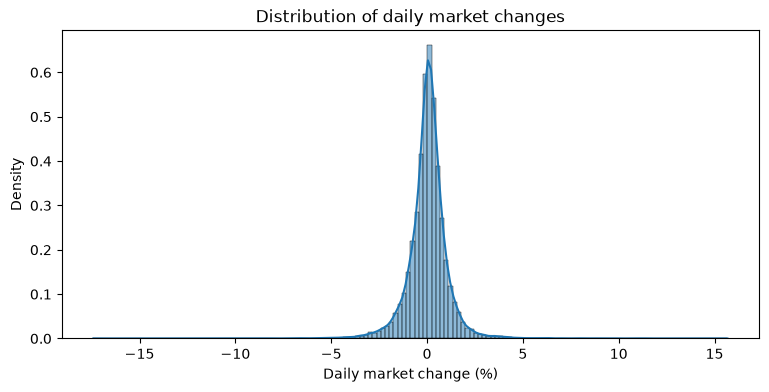

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

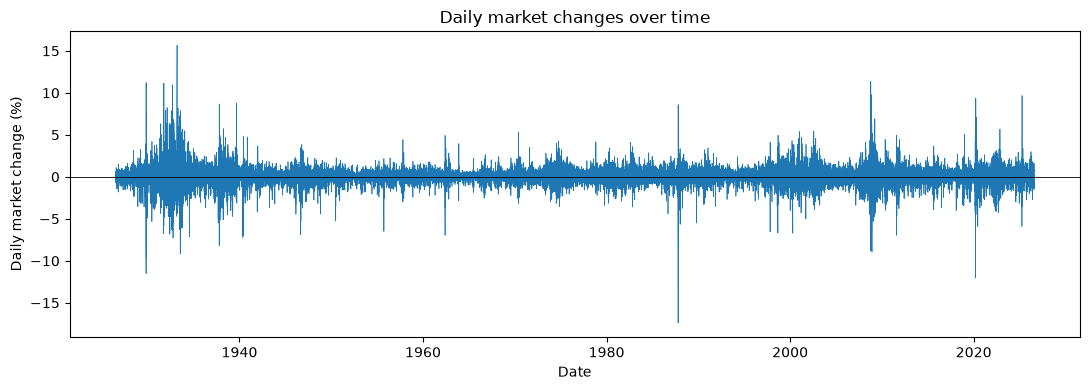

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
df['todayCat'] = np.where(df['market_return_pct'] > 0, 'Up', 'Down')
df['nextCat'] = df['todayCat'].shift(-1)
jointPMF = pd.crosstab(df['todayCat'], df['nextCat'], normalize=True, margins=True)
condPMF = pd.crosstab(df['todayCat'], df['nextCat'], normalize='index')

In [5]:
print("Joint PMF of today's and next day's market change categories:")
print(jointPMF)

Joint PMF of today's and next day's market change categories:
nextCat       Down        Up       All
todayCat                              
Down      0.224720  0.228142  0.452862
Up        0.228142  0.318996  0.547138
All       0.452862  0.547138  1.000000


In [6]:
print("\nConditional PMF of next day's market change category given today's category:")
print(condPMF)


Conditional PMF of next day's market change category given today's category:
nextCat       Down        Up
todayCat                    
Down      0.496221  0.503779
Up        0.416974  0.583026


1. Up transitions are more common than down transitions.
2. More likely to transition from an Up day.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [7]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ["Large loss", "Small loss", "Near zero", "Small gain", "Large gain"]

df["currentState"] = pd.cut(df['market_return_pct'], bins=bins, labels=labels)
df["currentState"].value_counts()

currentState
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

Small gain has 9785, small loss has 7452, near zero has 3441, large gain has 2859, and large loss has 2759. The most common is small gain and least common is large loss.

In [8]:
df["tomorrowState"] = df["currentState"].shift(-1)
jointPMFStates = pd.crosstab(df["currentState"], df["tomorrowState"], normalize=True, margins=True)
print("\nJoint PMF of today's and tomorrow's market change states:")
print(jointPMFStates)


Joint PMF of today's and tomorrow's market change states:
tomorrowState  Large loss  Small loss  Near zero  Small gain  Large gain  \
currentState                                                               
Large loss       0.021335    0.027191   0.009051    0.027800    0.019547   
Small loss       0.035444    0.088648   0.034151    0.097775    0.027382   
Near zero        0.009317    0.041985   0.020955    0.049325    0.009279   
Small gain       0.024986    0.100057   0.055029    0.159422    0.032592   
Large gain       0.013843    0.025518   0.011637    0.037802    0.019928   
All              0.104925    0.283400   0.130823    0.372124    0.108728   

tomorrowState       All  
currentState             
Large loss     0.104925  
Small loss     0.283400  
Near zero      0.130861  
Small gain     0.372086  
Large gain     0.108728  
All            1.000000  


Small gain to small gain is high at 16% and small gain to small loss is high at 10%.

In [9]:
condPMFStates = pd.crosstab(df["currentState"], df["tomorrowState"], normalize='index')
print("\nConditional PMF of tomorrow's market change state given today's state:")
print(condPMFStates)


Conditional PMF of tomorrow's market change state given today's state:
tomorrowState  Large loss  Small loss  Near zero  Small gain  Large gain
currentState                                                            
Large loss       0.203335    0.259152   0.086263    0.264951    0.186299
Small loss       0.125067    0.312802   0.120505    0.345008    0.096618
Near zero        0.071200    0.320837   0.160128    0.376925    0.070910
Small gain       0.067150    0.268908   0.147895    0.428455    0.087592
Large gain       0.127317    0.234697   0.107030    0.347674    0.183281


All transitions have small gain and small loss to most likely transition to.

Most of the transitions aren't that close to the uniform .2 and are more close to their baseline.

The next transition is hard to predict as the rows aren't uniform so today's state adds little. Small gain and small loss have the highest values, but it's more likely to go to the uniform values of 20% like large loss - large loss.

In [10]:
df["tomorrowReturnPct"] = df["market_return_pct"].shift(-1)
stateSummary = df.groupby("currentState")["tomorrowReturnPct"].describe()
print("\nSummary statistics of tomorrow's market change percentage by today's state:")
print(stateSummary)


Summary statistics of tomorrow's market change percentage by today's state:
               count      mean       std    min   25%   50%   75%    max
currentState                                                            
Large loss    2759.0 -0.038311  1.720570 -17.41 -0.79 -0.01  0.72  11.22
Small loss    7452.0 -0.043814  1.009529 -11.23 -0.53  0.01  0.45  11.36
Near zero     3441.0  0.015013  0.826054  -8.19 -0.35  0.03  0.42   5.49
Small gain    9784.0  0.106810  0.832186  -8.25 -0.25  0.12  0.50   8.67
Large gain    2859.0  0.163092  1.384086 -12.00 -0.37  0.15  0.73  15.67


The expected percent returns are usually the mean for each state: Large loss to -0.04, small loss to -0.04, near zero to 0.02, small gain to 0.1, and large gain to 0.16. Large loss, small loss, and large gain are seen to have the way smaller mins and way bigger maxes, and near zero and small gain are seen to have larger mins and smaller maxes. Large loss has the highest standard deviation for tomorrow's state. 

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [11]:
df["y_t"] = pd.qcut(df['market_return_pct'], q=21, labels=False)
df["y_tp1"] = df["y_t"].shift(-1)

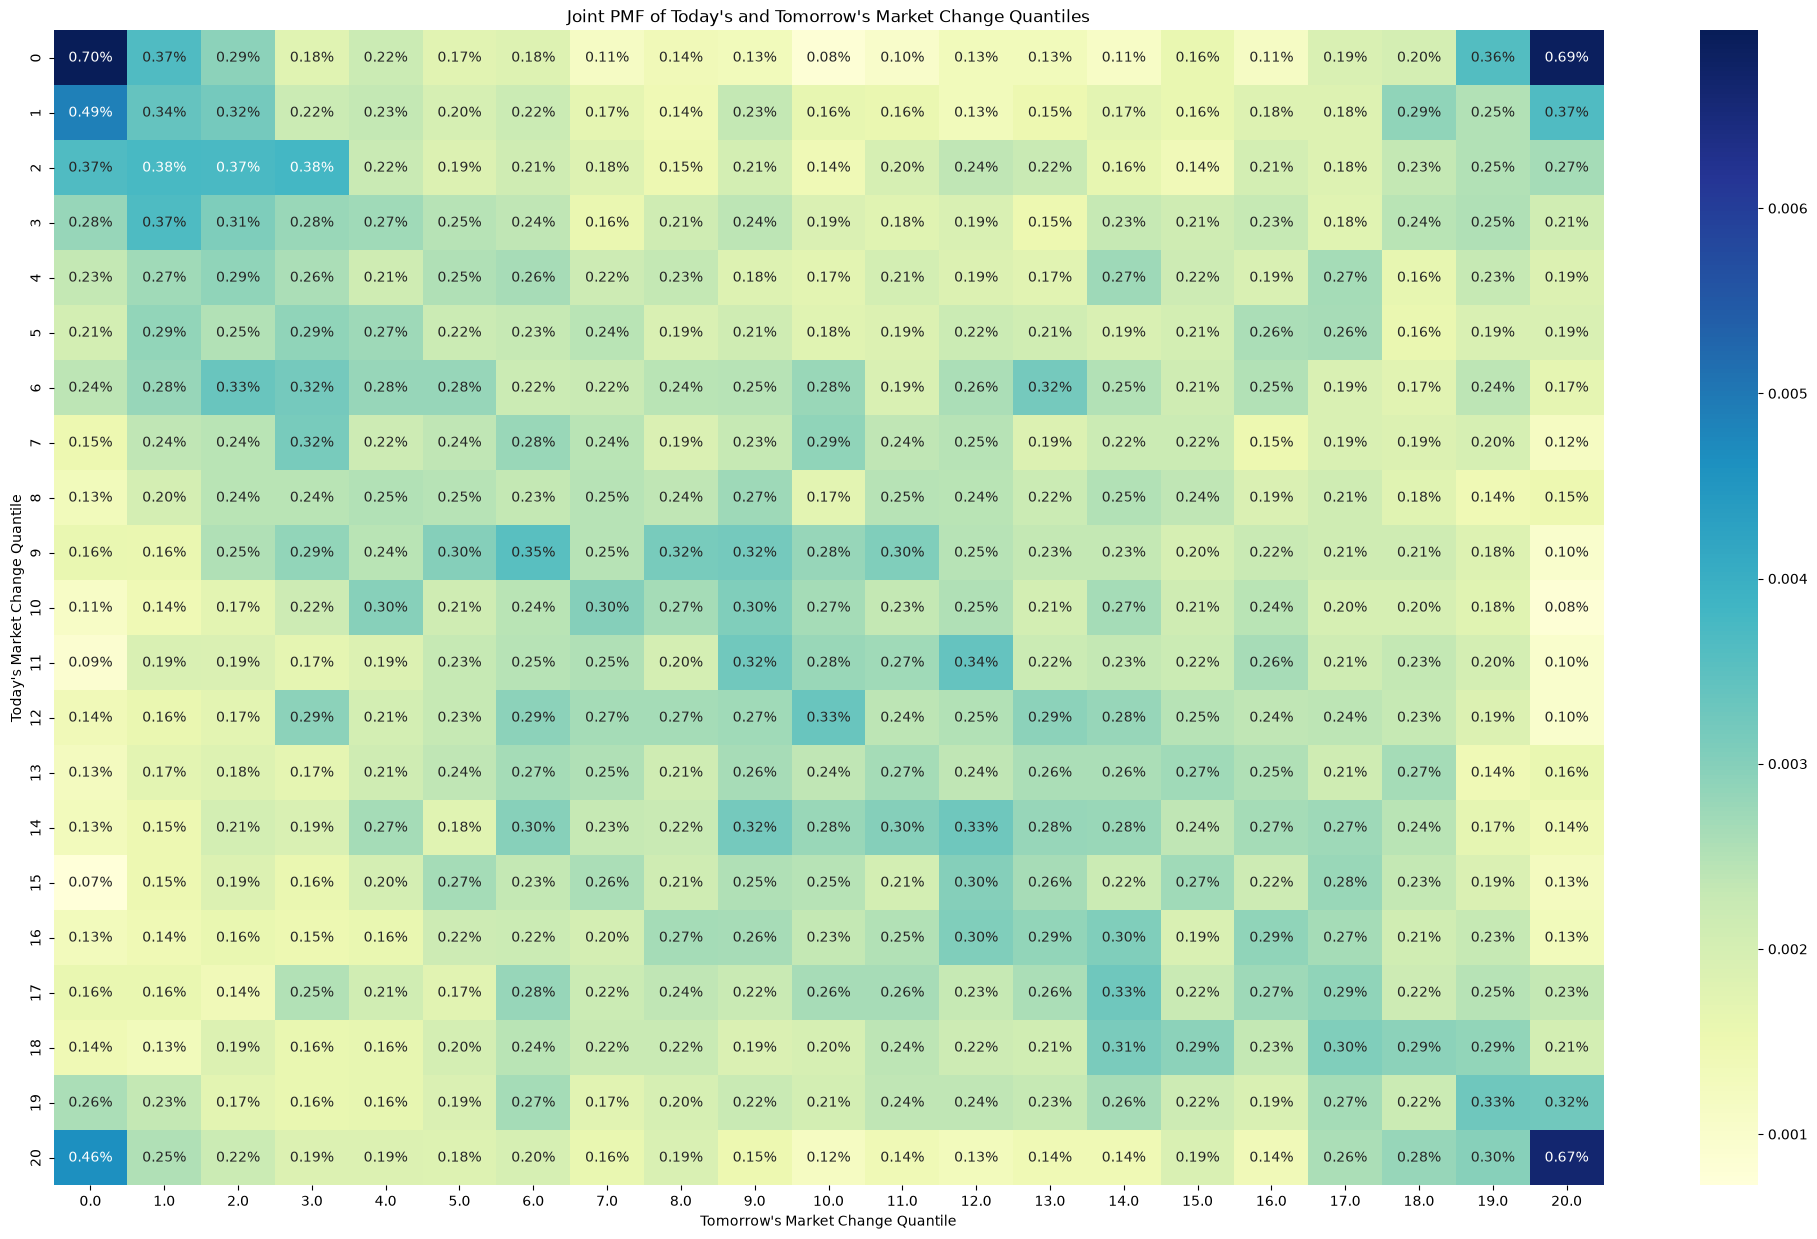

In [12]:
jointPMFQuantiles = pd.crosstab(df["y_t"], df["y_tp1"], normalize=True)

fig, ax = plt.subplots(figsize=(25, 15))
sns.heatmap(jointPMFQuantiles, annot=True, fmt=".2%", cmap="YlGnBu", ax=ax)
ax.set(xlabel="Tomorrow's Market Change Quantile", ylabel="Today's Market Change Quantile",
       title="Joint PMF of Today's and Tomorrow's Market Change Quantiles")
plt.show()

In the corners, the percentages are the higest and the other percentages lead up to them. This means values are more mlikely to transitions to values of themselves or to the center shared uniform of each other.

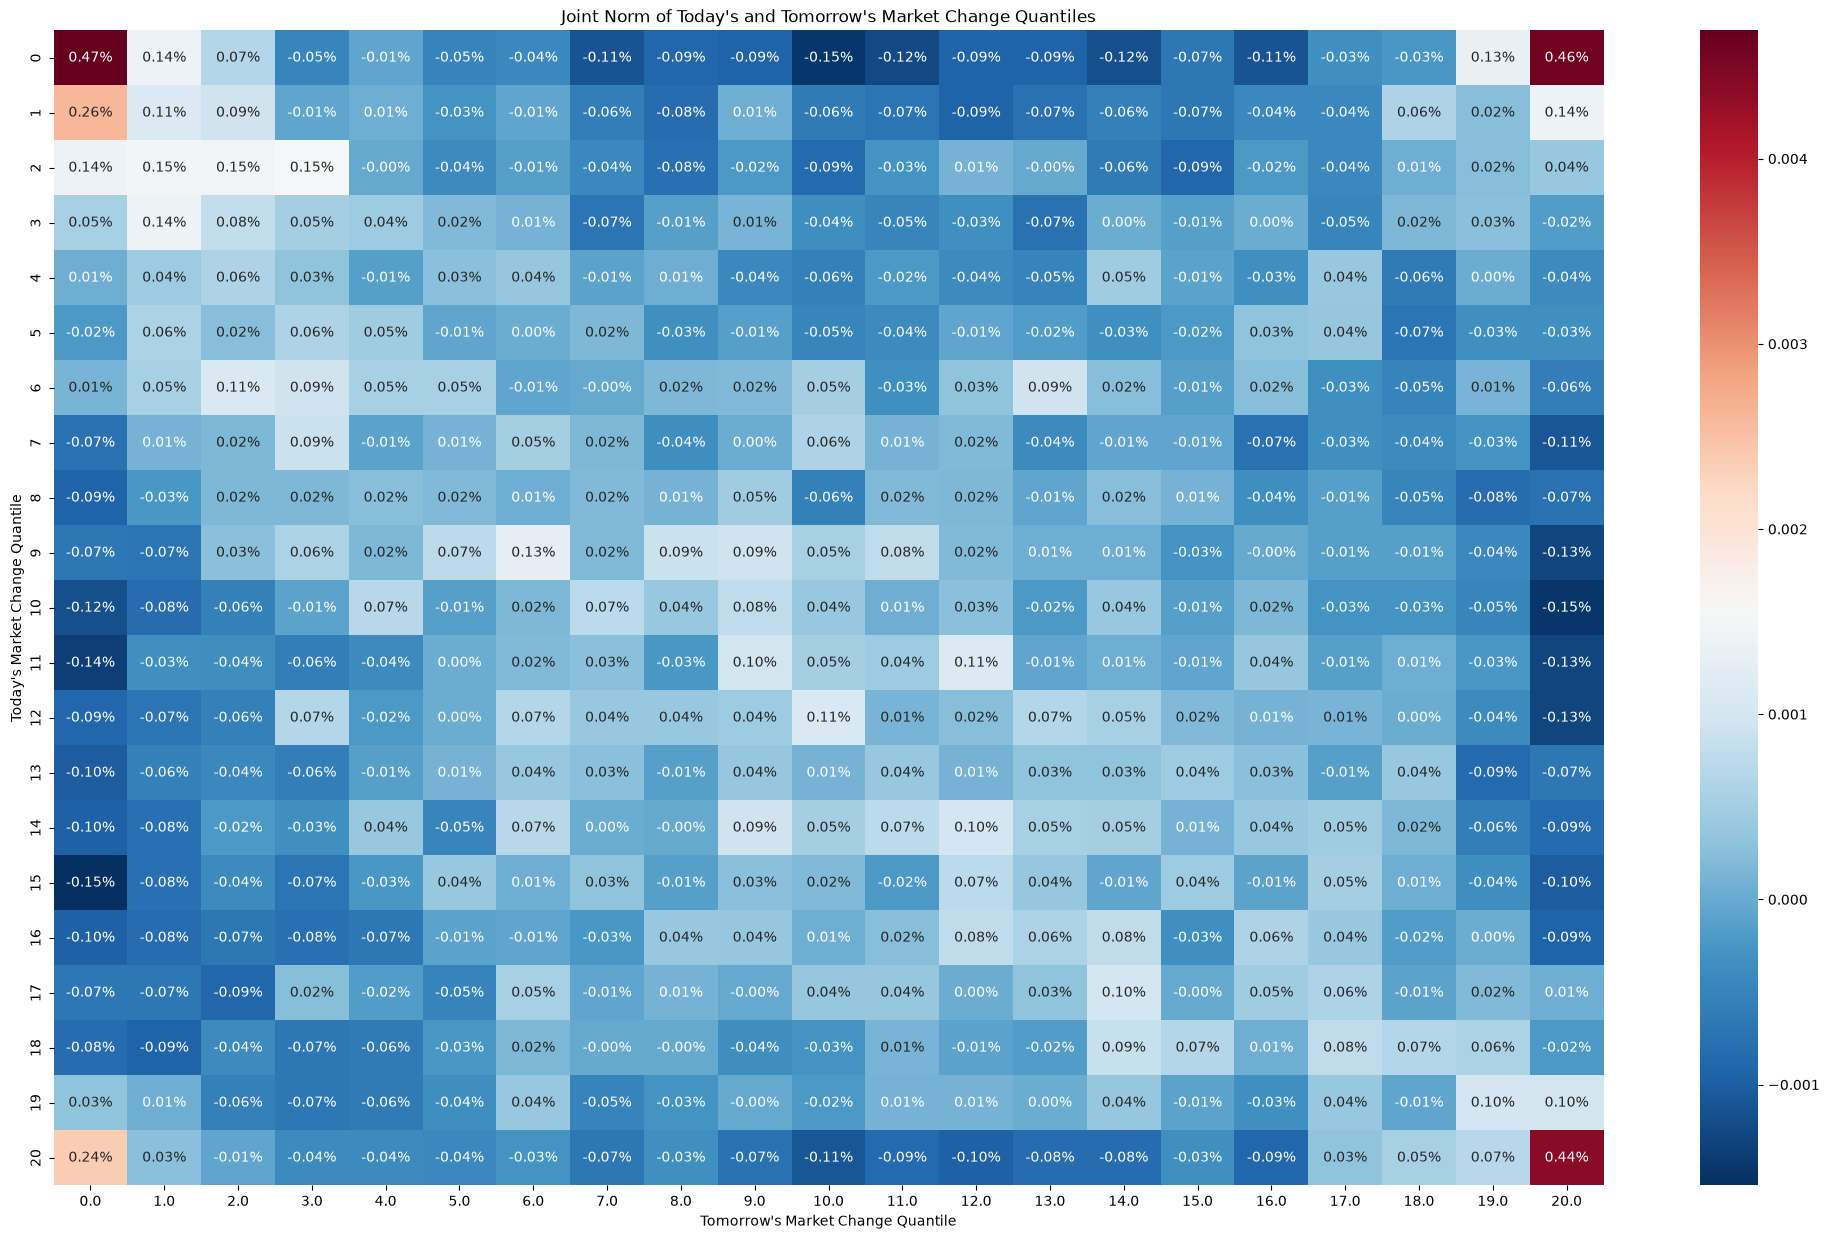

In [13]:
jointNorm = jointPMFQuantiles - (1 / 21 ** 2)

fig, ax = plt.subplots(figsize=(25, 15))
sns.heatmap(jointNorm, annot=True, fmt=".2%", cmap="RdBu_r", ax=ax)
ax.set(xlabel="Tomorrow's Market Change Quantile", ylabel="Today's Market Change Quantile",
       title="Joint Norm of Today's and Tomorrow's Market Change Quantiles")
plt.show()

Same deal with the percentages at the corner, except they are smaller.

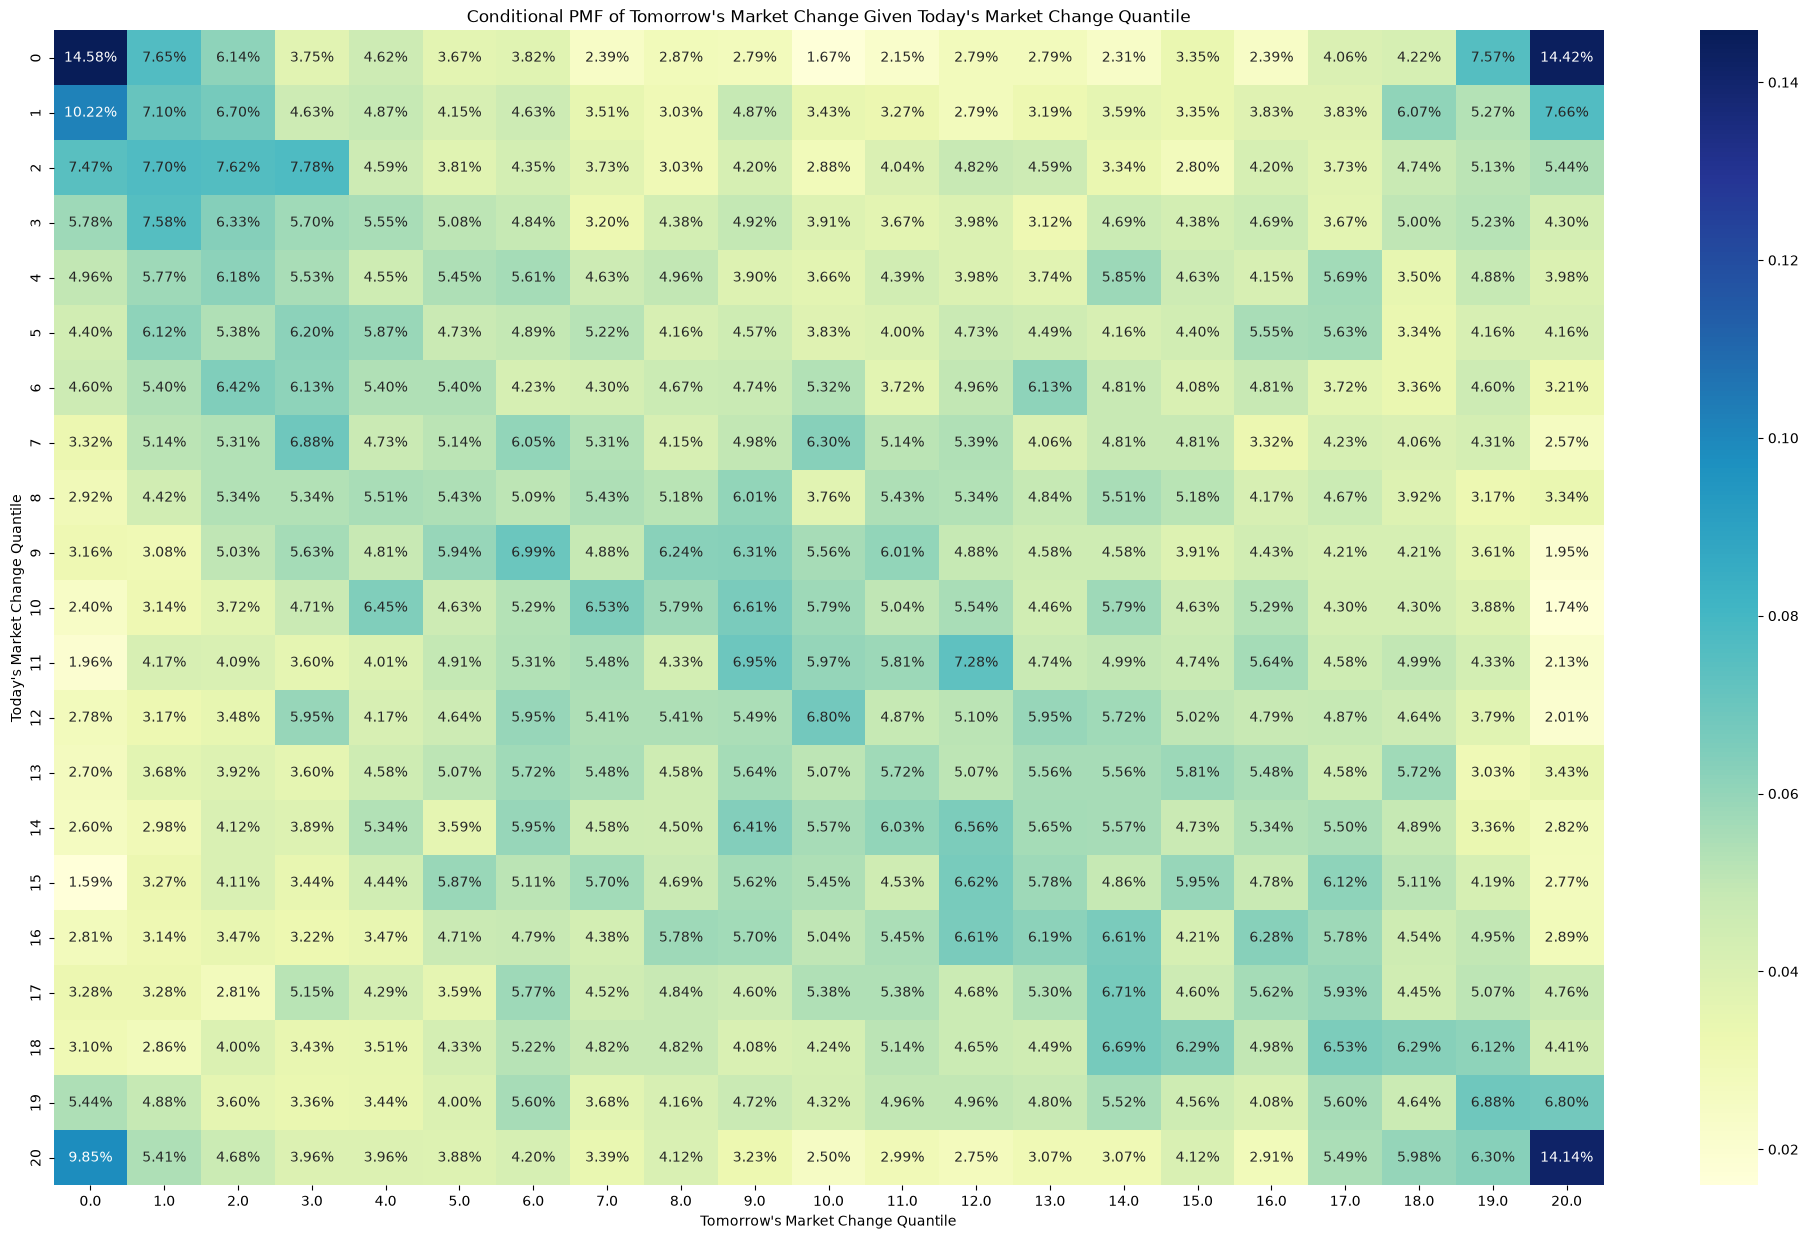

In [14]:
condPMFQuantiles = pd.crosstab(df["y_t"], df["y_tp1"], normalize='index')
fig, ax = plt.subplots(figsize=(25, 15))
sns.heatmap(condPMFQuantiles, annot=True, fmt=".2%", cmap="YlGnBu", ax=ax)
ax.set(xlabel="Tomorrow's Market Change Quantile", ylabel="Today's Market Change Quantile",
       title="Conditional PMF of Tomorrow's Market Change Given Today's Market Change Quantile")
plt.show()

The corners are the highest probability with the other highs one being around them or in the center. Meaning it has extreme values of having transitions go from similar values to similar values or to the center of the bins.

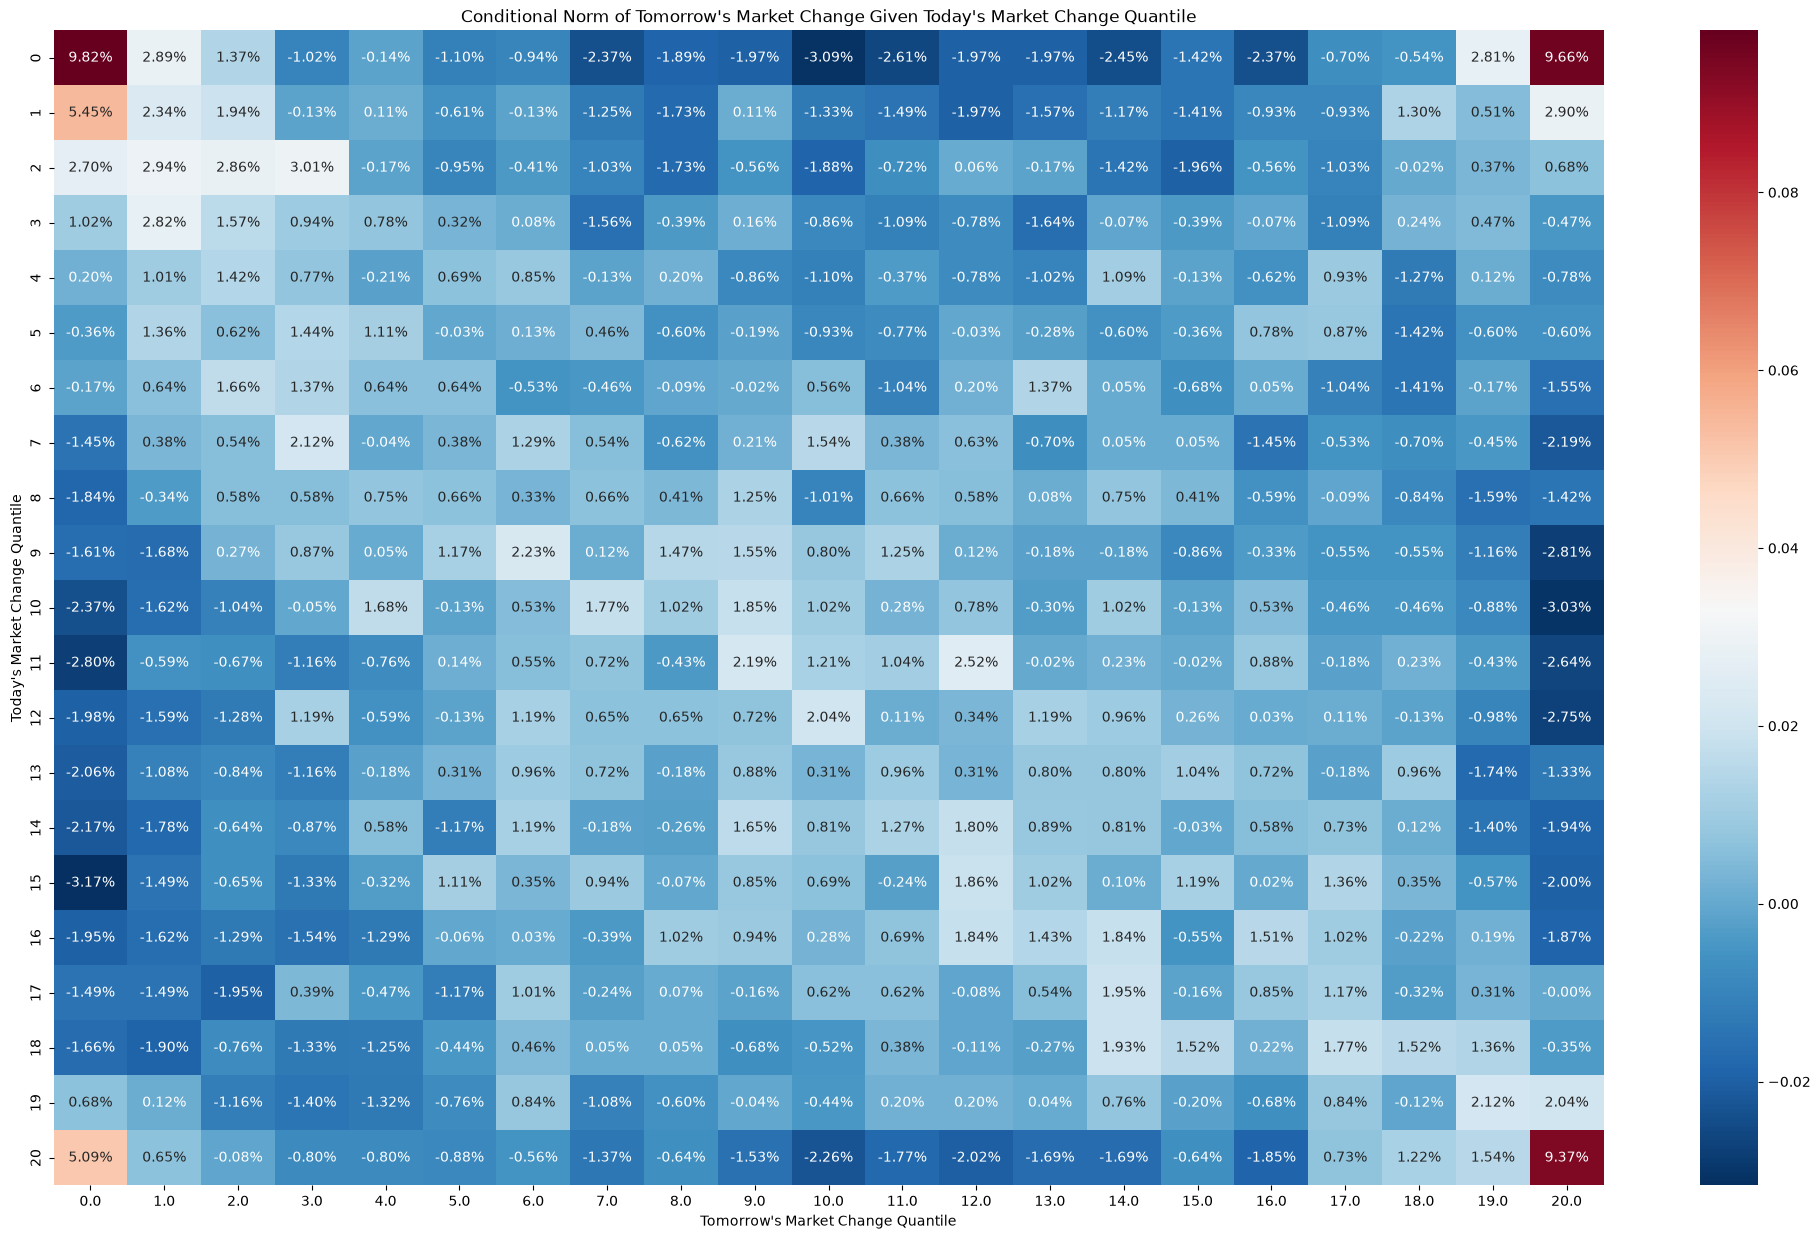

In [15]:
condNorm = condPMFQuantiles - (1 / 21)
fig, ax = plt.subplots(figsize=(25, 15))
sns.heatmap(condNorm, annot=True, fmt=".2%", cmap="RdBu_r", ax=ax)
ax.set(xlabel="Tomorrow's Market Change Quantile", ylabel="Today's Market Change Quantile",
       title="Conditional Norm of Tomorrow's Market Change Given Today's Market Change Quantile")
plt.show()

Same deal with before, just smaller probabilities.

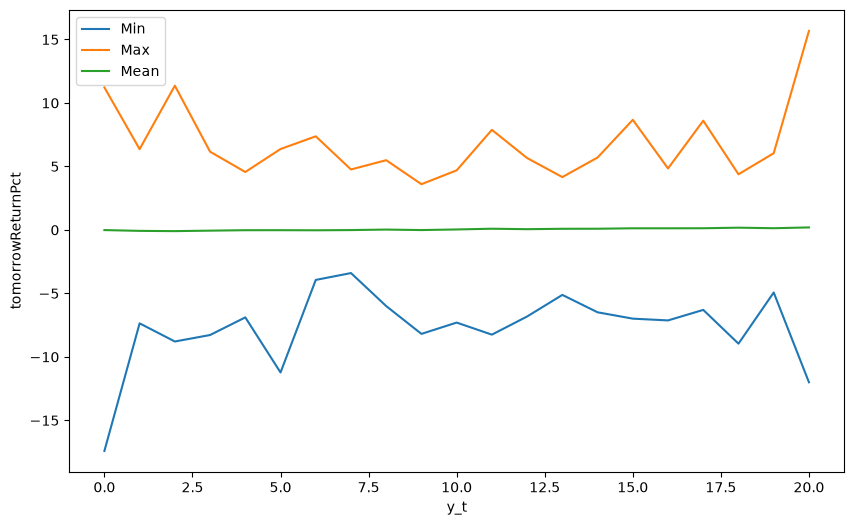

In [16]:
binValues = df.groupby("y_t")["tomorrowReturnPct"].agg(["min", "mean", "max", "std"])
plt.figure(figsize=(10, 6))
plt.plot(binValues.index, binValues["min"], label="Min")
plt.plot(binValues.index, binValues["max"], label="Max")
plt.plot(binValues.index, binValues["mean"], label="Mean")
plt.xlabel("y_t")
plt.ylabel("tomorrowReturnPct")
plt.legend()
plt.show()

It shows the min going up and down from the range -17 to -3, max goung up and down from 3 to 17, and  the mean in the middle at 0.

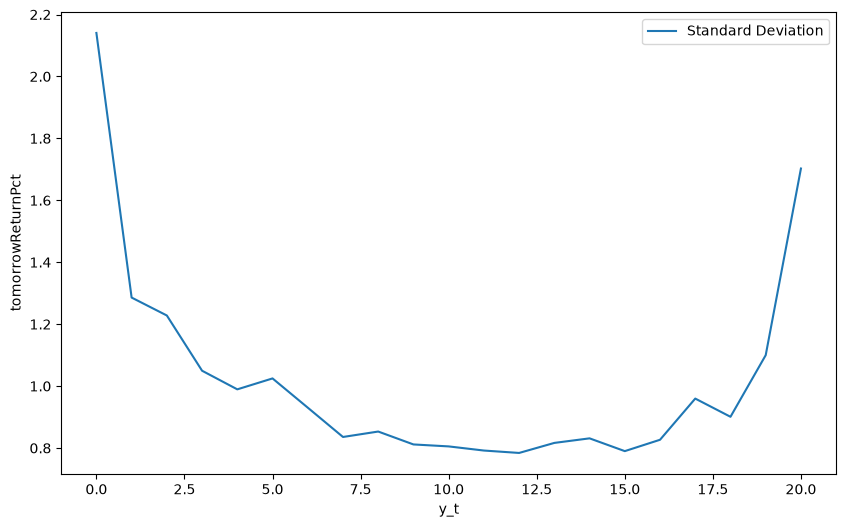

In [17]:
plt.figure(figsize=(10, 6))
plt.plot(binValues.index, binValues["std"], label="Standard Deviation")
plt.xlabel("y_t")
plt.ylabel("tomorrowReturnPct")
plt.legend()
plt.show()

Standard deviation gives a giant U shape line starting from nearly 2.2, going roughly low to 0.8, and then going up to 1.7.

It will be really hard to predict the market because there will still be extreme values that won't be able to give the full answer since they can reverse easily as they continue. The conditional mean sits near 0 while the spread is large, and the size of the next move is unpredictable because of extreme values.